In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn

from torchvision import datasets, transforms, models
from torch.utils.data import DataLoader

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

print("Evaluation libraries imported successfully.")

Evaluation libraries imported successfully.


In [2]:
# ============================================
# Cell 2: Evaluation Configuration
# ============================================

PROJECT_DIR = Path.cwd().parent

DATASET_DIR = PROJECT_DIR / "dataset"

TEST_DIR = DATASET_DIR / "test"

MODEL_PATH = (
    PROJECT_DIR
    / "models"
    / "efficientnet_b0_finetuned_best.pth"
)

RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

IMG_SIZE = 224
BATCH_SIZE = 16
NUM_CLASSES = 2

DEVICE = torch.device("cpu")


print("Project directory :", PROJECT_DIR)
print("Test directory    :", TEST_DIR)
print("Model path        :", MODEL_PATH)
print("Results directory :", RESULTS_DIR)
print("Device            :", DEVICE)

print("\nPaths verified:")
print("Test directory exists :", TEST_DIR.exists())
print("Model exists          :", MODEL_PATH.exists())

Project directory : d:\deepfake
Test directory    : d:\deepfake\dataset\test
Model path        : d:\deepfake\models\efficientnet_b0_finetuned_best.pth
Results directory : d:\deepfake\results
Device            : cpu

Paths verified:
Test directory exists : True
Model exists          : True


In [3]:
# ============================================
# Cell 3: Test Dataset and DataLoader
# ============================================

test_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

test_dataset = datasets.ImageFolder(
    TEST_DIR,
    transform=test_transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0
)

print("Class mapping:", test_dataset.class_to_idx)
print("Number of test images:", len(test_dataset))
print("Number of test batches:", len(test_loader))

Class mapping: {'fake': 0, 'real': 1}
Number of test images: 307
Number of test batches: 20


In [4]:
# ============================================
# Cell 4: Load Final EfficientNet-B0 Model
# ============================================

model = models.efficientnet_b0(
    weights=None
)

# Replace ImageNet classifier with 2-class classifier
model.classifier[1] = nn.Linear(
    model.classifier[1].in_features,
    NUM_CLASSES
)

# Load our trained weights
checkpoint = torch.load(
    MODEL_PATH,
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(checkpoint)

model = model.to(DEVICE)

model.eval()

print("Final EfficientNet-B0 model loaded successfully.")

print("\nClassifier:")
print(model.classifier)

print("\nDevice:", DEVICE)

Final EfficientNet-B0 model loaded successfully.

Classifier:
Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=2, bias=True)
)

Device: cpu


In [5]:
# ============================================
# Cell 5: Generate Test Predictions
# ============================================

all_predictions = []
all_labels = []
all_probabilities = []

model.eval()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(DEVICE)
        labels = labels.to(DEVICE)

        # Forward pass
        outputs = model(images)

        # Convert logits to probabilities
        probabilities = torch.softmax(
            outputs,
            dim=1
        )

        # Get predicted class
        predictions = torch.argmax(
            probabilities,
            dim=1
        )

        # Store results
        all_predictions.extend(
            predictions.cpu().numpy()
        )

        all_labels.extend(
            labels.cpu().numpy()
        )

        all_probabilities.extend(
            probabilities.cpu().numpy()
        )


# Convert to NumPy arrays
all_predictions = np.array(
    all_predictions
)

all_labels = np.array(
    all_labels
)

all_probabilities = np.array(
    all_probabilities
)


print("Prediction completed successfully.")

print()
print("Number of predictions :", len(all_predictions))
print("Number of labels      :", len(all_labels))
print("Probability shape     :", all_probabilities.shape)

Prediction completed successfully.

Number of predictions : 307
Number of labels      : 307
Probability shape     : (307, 2)


In [6]:
# ============================================
# Cell 6: Final Evaluation Metrics
# ============================================

# Calculate accuracy
final_accuracy = accuracy_score(
    all_labels,
    all_predictions
)

print("=" * 60)
print("FINAL MODEL EVALUATION")
print("=" * 60)

print(
    f"Test Accuracy : {final_accuracy:.4f}"
)

print(
    f"Test Accuracy : {final_accuracy * 100:.2f}%"
)


# ============================================
# Classification Report
# ============================================

report = classification_report(
    all_labels,
    all_predictions,
    target_names=["Fake", "Real"],
    digits=4
)

print("\nClassification Report:")
print(report)

FINAL MODEL EVALUATION
Test Accuracy : 0.6515
Test Accuracy : 65.15%

Classification Report:
              precision    recall  f1-score   support

        Fake     0.6350    0.6042    0.6192       144
        Real     0.6647    0.6933    0.6787       163

    accuracy                         0.6515       307
   macro avg     0.6499    0.6487    0.6489       307
weighted avg     0.6508    0.6515    0.6508       307



In [7]:
# ============================================
# Cell 7: Save Classification Report
# ============================================

report_path = (
    RESULTS_DIR
    / "final_classification_report.txt"
)

with open(
    report_path,
    "w",
    encoding="utf-8"
) as f:

    f.write(
        "DEEPFAKE DETECTION - FINAL MODEL EVALUATION\n"
    )

    f.write(
        "=" * 60 + "\n\n"
    )

    f.write(
        "Model: EfficientNet-B0 Fine-Tuned\n"
    )

    f.write(
        "Input: Full Image\n"
    )

    f.write(
        f"Test Accuracy: "
        f"{final_accuracy * 100:.2f}%\n\n"
    )

    f.write(
        "Classification Report:\n"
    )

    f.write(report)


print("Classification report saved successfully.")
print(f"Saved at: {report_path}")

Classification report saved successfully.
Saved at: d:\deepfake\results\final_classification_report.txt


Final Confusion Matrix:
[[ 87  57]
 [ 50 113]]


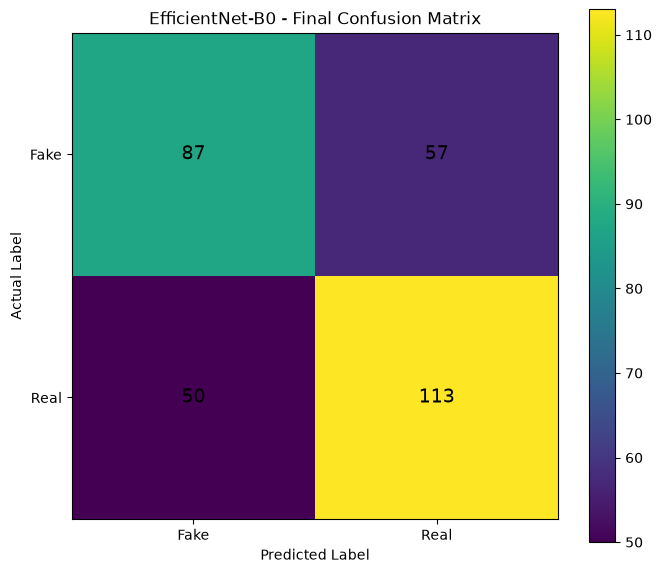


Confusion matrix saved at:
d:\deepfake\results\final_confusion_matrix.png


In [8]:
# ============================================
# Cell 8: Final Confusion Matrix
# ============================================

cm = confusion_matrix(
    all_labels,
    all_predictions
)

print("Final Confusion Matrix:")
print(cm)


# ============================================
# Plot confusion matrix
# ============================================

plt.figure(figsize=(7, 6))

plt.imshow(cm)

plt.title(
    "EfficientNet-B0 - Final Confusion Matrix"
)

plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.xticks(
    [0, 1],
    ["Fake", "Real"]
)

plt.yticks(
    [0, 1],
    ["Fake", "Real"]
)


# Add values to cells
for i in range(2):

    for j in range(2):

        plt.text(
            j,
            i,
            cm[i, j],
            ha="center",
            va="center",
            fontsize=14
        )


plt.colorbar()

plt.tight_layout()


# ============================================
# Save figure
# ============================================

confusion_matrix_path = (
    RESULTS_DIR
    / "final_confusion_matrix.png"
)

plt.savefig(
    confusion_matrix_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print()
print(
    f"Confusion matrix saved at:"
)

print(
    confusion_matrix_path
)

In [9]:
# ============================================
# Cell 9: Model Comparison
# ============================================

comparison = pd.DataFrame({
    "Experiment": [
        "Full Image + EfficientNet-B0 Fine-Tuned",
        "Face Crop + EfficientNet-B0 Fine-Tuned"
    ],
    "Test_Accuracy": [
        65.15,
        62.22
    ]
})

comparison["Test_Accuracy_Percent"] = (
    comparison["Test_Accuracy"]
)

comparison_path = (
    RESULTS_DIR
    / "model_comparison.csv"
)

comparison.to_csv(
    comparison_path,
    index=False
)

print("Model comparison:")
print(comparison)

print()
print(
    f"Comparison saved at:"
)

print(comparison_path)

Model comparison:
                                Experiment  Test_Accuracy  \
0  Full Image + EfficientNet-B0 Fine-Tuned          65.15   
1   Face Crop + EfficientNet-B0 Fine-Tuned          62.22   

   Test_Accuracy_Percent  
0                  65.15  
1                  62.22  

Comparison saved at:
d:\deepfake\results\model_comparison.csv


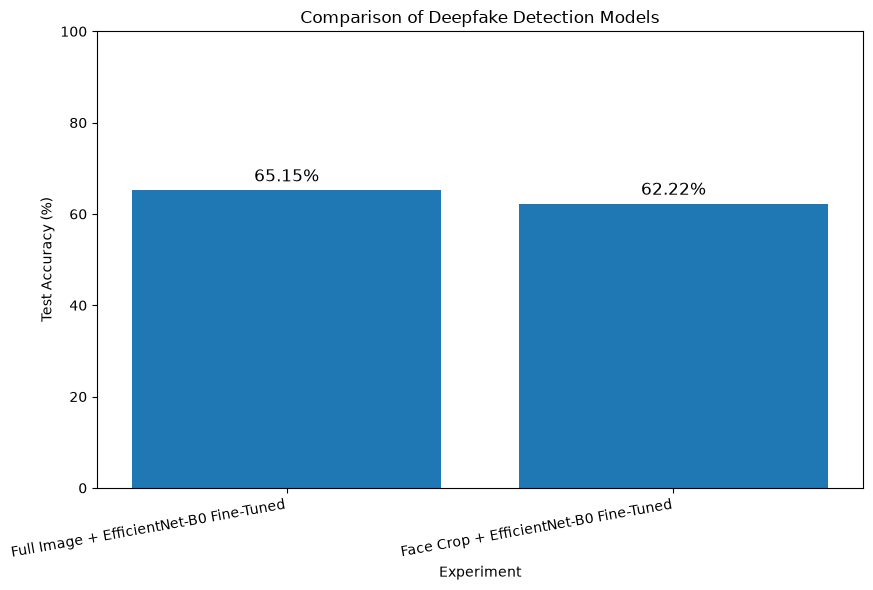

Model comparison chart saved at:
d:\deepfake\results\model_comparison.png


In [10]:
# ============================================
# Cell 10: Model Comparison Chart
# ============================================

plt.figure(figsize=(9, 6))

plt.bar(
    comparison["Experiment"],
    comparison["Test_Accuracy"]
)

plt.ylabel("Test Accuracy (%)")
plt.xlabel("Experiment")

plt.title(
    "Comparison of Deepfake Detection Models"
)

plt.ylim(0, 100)

# Display accuracy values above bars
for i, value in enumerate(
    comparison["Test_Accuracy"]
):

    plt.text(
        i,
        value + 2,
        f"{value:.2f}%",
        ha="center",
        fontsize=12
    )

plt.xticks(
    rotation=10,
    ha="right"
)

plt.tight_layout()


# ============================================
# Save chart
# ============================================

comparison_plot_path = (
    RESULTS_DIR
    / "model_comparison.png"
)

plt.savefig(
    comparison_plot_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(
    f"Model comparison chart saved at:"
)

print(comparison_plot_path)